In [35]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Implementacja sieci

In [36]:
class sigmoid():
    def __init__(self):
        pass

    def forward(self, x):
        return 1 / (1 + np.exp(-x))

In [37]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych
        self.wagi = np.ones((liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        return np.dot(x, self.wagi) + self.bias

In [38]:
class MLP():
    def __init__(self, warstwy):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x

# Szukanie wag przez PyTorch

In [48]:
def znajdz_wagi (model, data, test_data, dlugosc_treningu):
    czy_znormalizowac = True
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # Przygotuj dane uczące
    x_list = data['x'].tolist()
    y_list = data['y'].tolist()

    # Przygotuj dane testujące
    test_x_list = test_data['x'].tolist()
    test_y_list = test_data['y'].tolist()

    # Treninig
    print("Zbiór treningowy")
    for i in range(dlugosc_treningu):
        x_to_plot = []
        y_to_plot = []
        y_pred_to_plot = []

        x = torch.tensor(x_list).reshape(-1,1).to(device)
        y = torch.tensor(y_list).reshape(-1,1).to(device)

        if czy_znormalizowac:
            x_min = x.min()
            x_max = x.max()
            y_min = y.min()
            y_max = y.max()

            x_normalized = (x - x_min) / (x_max - x_min)
            y_normalized = (y - y_min) / (y_max - y_min)
        else:
            x_normalized = x
            y_normalized = y

        y_pred = model(x_normalized)

        x_to_plot = x_to_plot + x.tolist()
        y_to_plot = y_to_plot + y.tolist()
        y_pred_to_plot = y_pred_to_plot + (y_pred*(y.max() - y.min()) + y.min()).tolist()

        loss = criterion(y_pred, y_normalized)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if czy_znormalizowac:
        print(f"Znormalizowana finalna wartość funkcji straty: {loss.item()}")
        normalized_loss = criterion( y_pred*(y_max - y_min) + y_min , y)
        print(f"Nieznormalizowana finalna wartość funkcji straty: {normalized_loss.item()}")
    else:
        print(f"Nieznormalizowana finalna wartość funkcji straty: {loss.item()}")

    plt.scatter(x_to_plot, y_to_plot)
    plt.scatter(x_to_plot, y_pred_to_plot)
    plt.legend(['Prawdziwa wartość', 'Przewidziana wartość'])
    plt.title('Wartości na zbiorze treningowym')
    plt.show()

    # Testowanie
    print("Zbiór testowy")
    test_x_to_plot = []
    test_y_to_plot = []
    test_y_pred_to_plot = []

    x = torch.tensor(test_x_list).reshape(-1,1).to(device)
    y = torch.tensor(test_y_list).reshape(-1,1).to(device)

    if czy_znormalizowac:
        x_normalized = (x - x_min) / (x_max - x_min)
        y_normalized = (y - y_min) / (y_max - y_min)
    else:
        x_normalized = x
        y_normalized = y

    y_pred = model(x_normalized)

    test_x_to_plot = test_x_to_plot + x.tolist()
    test_y_to_plot = test_y_to_plot + y.tolist()
    test_y_pred_to_plot = test_y_pred_to_plot + (y_pred*(y_max - y_min) + y_min).tolist()

    loss = criterion(y_pred, y_normalized)

    if czy_znormalizowac:
        print(f"Znormalizowana finalna wartość funkcji straty: {loss.item()}")
        normalized_loss = criterion( y_pred*(y_max - y_min) + y_min , y)
        print(f"Nieznormalizowana finalna wartość funkcji straty: {normalized_loss.item()}")
    else:
        print(f"Nieznormalizowana finalna wartość funkcji straty: {loss.item()}")

    plt.scatter(test_x_to_plot, test_y_to_plot)
    plt.scatter(test_x_to_plot, test_y_pred_to_plot)
    plt.legend(['Prawdziwa wartość', 'Przewidziana wartość'])
    plt.title('Wartości na zbiorze testowym')
    plt.show()

In [49]:
square_simple_test = pd.read_csv("mio1/regression/square-simple-test.csv")
square_simple_train = pd.read_csv("mio1/regression/square-simple-training.csv")
steps_large_test = pd.read_csv("mio1/regression/steps-large-test.csv")
steps_large_train = pd.read_csv("mio1/regression/steps-large-training.csv")

In [50]:
model_5_steps = nn.Sequential(nn.Linear(1,5), nn.Sigmoid(), nn.Linear(5,1))
model_10_steps = nn.Sequential(nn.Linear(1,10), nn.Sigmoid(), nn.Linear(10,1))
model_2_5_steps = nn.Sequential(nn.Linear(1,5), nn.Sigmoid(), nn.Linear(5,5), nn.Sigmoid(), nn.Linear(5,1))

model_5_square = nn.Sequential(nn.Linear(1,5), nn.Sigmoid(), nn.Linear(5,1))
model_10_square = nn.Sequential(nn.Linear(1,10), nn.Sigmoid(), nn.Linear(10,1))
model_2_5_square = nn.Sequential(nn.Linear(1,5), nn.Sigmoid(), nn.Linear(5,5), nn.Sigmoid(), nn.Linear(5,1))

In [51]:
dlugosc_treningu_square = 50000
dlugosc_treningu_steps = 30000

### Dane square-simple

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 2.761933615147427e-07
Nieznormalizowana finalna wartość funkcji straty: 0.03167720139026642


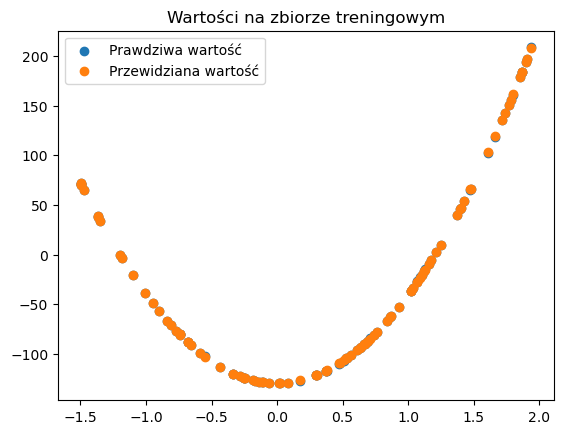

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 3.487186859274516e-07
Nieznormalizowana finalna wartość funkcji straty: 0.03999568149447441


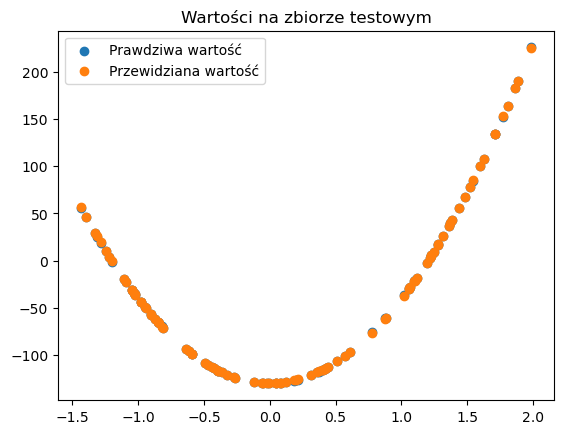

In [52]:
znajdz_wagi(model_5_square, square_simple_train, square_simple_test, dlugosc_treningu_square)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 7.267089472406951e-07
Nieznormalizowana finalna wartość funkcji straty: 0.08334898948669434


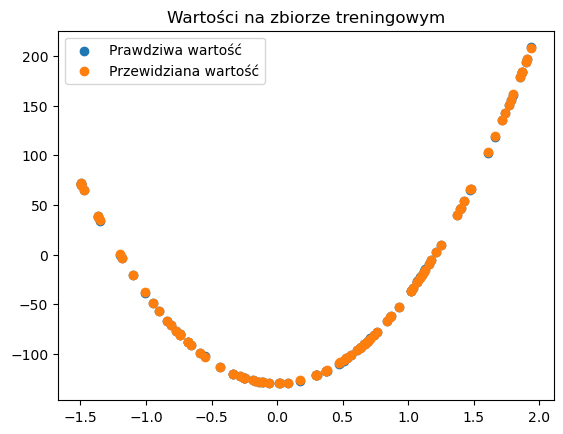

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 9.980027471101494e-07
Nieznormalizowana finalna wartość funkcji straty: 0.11446410417556763


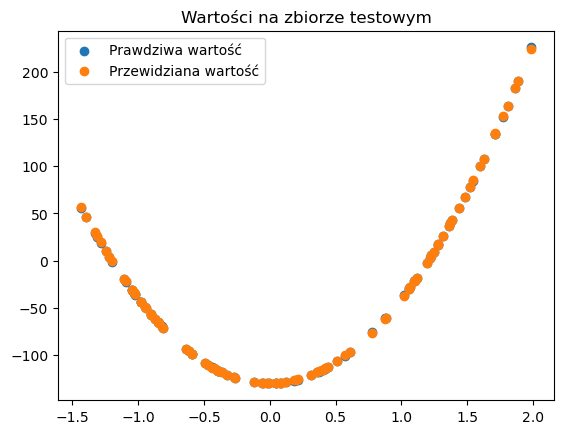

In [53]:
znajdz_wagi(model_10_square, square_simple_train, square_simple_test, dlugosc_treningu_square)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 7.200657137218514e-07
Nieznormalizowana finalna wartość funkcji straty: 0.08258597552776337


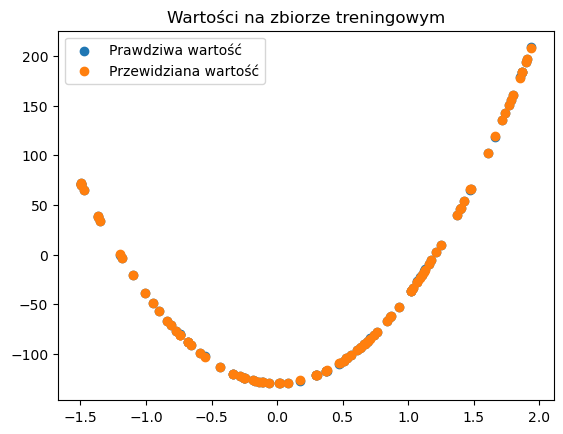

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 1.1218724011996528e-06
Nieznormalizowana finalna wartość funkcji straty: 0.12867091596126556


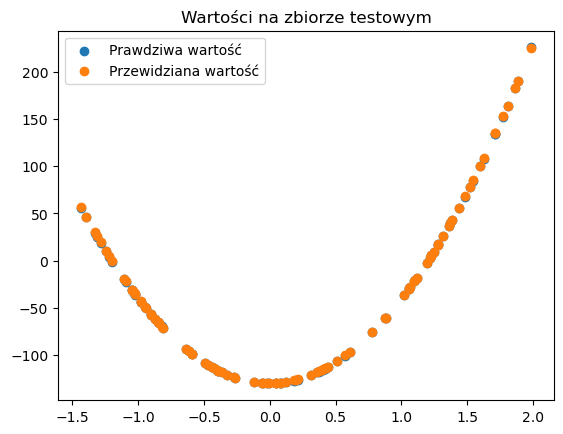

In [54]:
znajdz_wagi(model_2_5_square, square_simple_train, square_simple_test, dlugosc_treningu_square)

### Dane steps-large

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 0.006166120991110802
Nieznormalizowana finalna wartość funkcji straty: 355.1685791015625


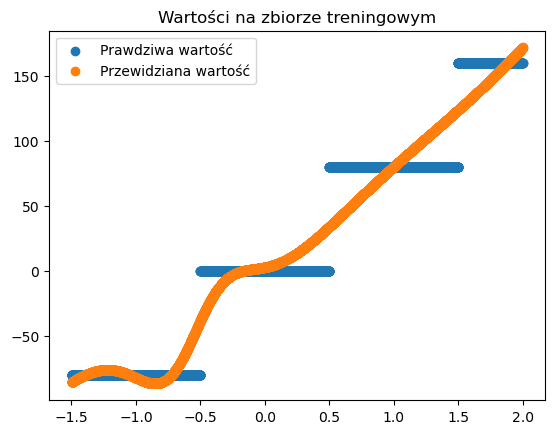

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 0.006157419178634882
Nieznormalizowana finalna wartość funkcji straty: 354.6673583984375


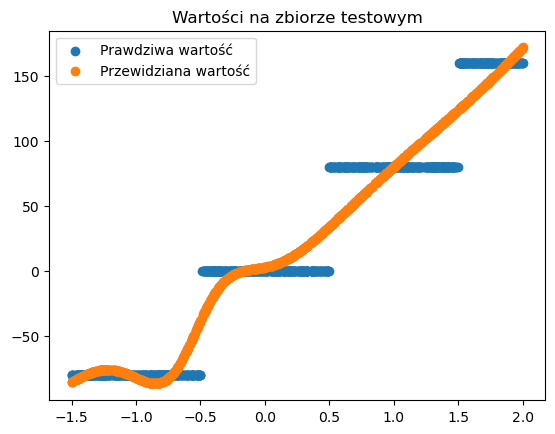

In [12]:
znajdz_wagi(model_5_steps, steps_large_train, steps_large_test, dlugosc_treningu_steps)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 0.006014925427734852
Nieznormalizowana finalna wartość funkcji straty: 346.4596862792969


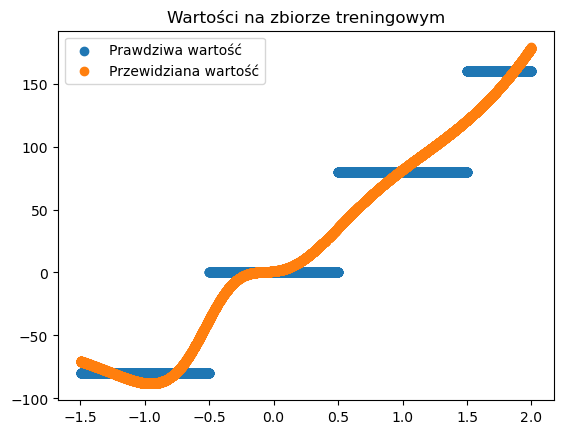

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 0.0060223666951060295
Nieznormalizowana finalna wartość funkcji straty: 346.8883056640625


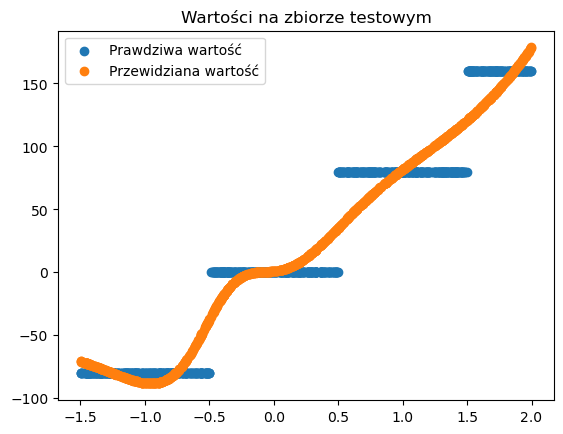

In [13]:
znajdz_wagi(model_10_steps, steps_large_train, steps_large_test, dlugosc_treningu_steps)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 0.0017929839668795466
Nieznormalizowana finalna wartość funkcji straty: 103.27587127685547


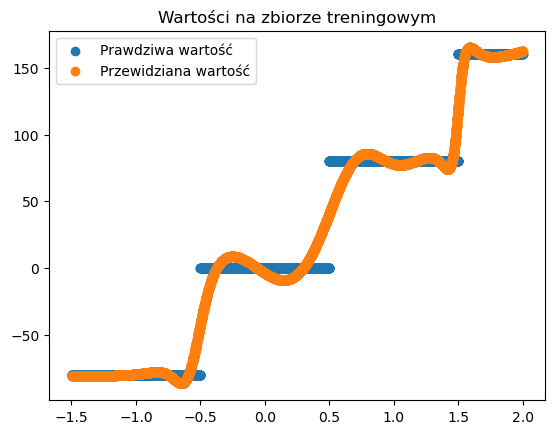

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 0.0015921160811558366
Nieznormalizowana finalna wartość funkcji straty: 91.70587921142578


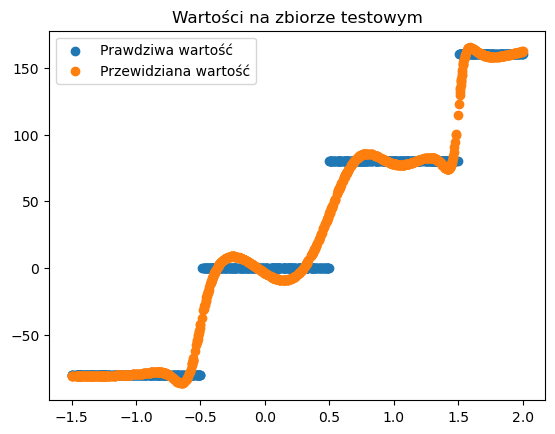

In [14]:
znajdz_wagi(model_2_5_steps, steps_large_train, steps_large_test, dlugosc_treningu_steps)

# Regresja na zbudowanym modelu

In [55]:
def run_mlp(model, X_train, y_train, X_test, y_test):
    # Skalowanie
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)

    y_min = y_train.min(axis=0)
    y_max = y_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    y_train_scaled = (y_train - y_min) / (y_max - y_min)

    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    y_test_scaled = (y_test - y_min) / (y_max - y_min)

    print("Zbiór treningowy")

    # Predykcja i liczenie MSE
    y_pred_train_scaled = model.forward(X_train_scaled)
    mse_train_norm = np.mean((y_train_scaled - y_pred_train_scaled) ** 2)
    print(f"Znormalizowana finalna wartość funkcji straty: {mse_train_norm}")

    y_pred_train = y_pred_train_scaled * (y_max - y_min) + y_min
    mse_train = np.mean((y_train - y_pred_train) ** 2)
    print(f"Nieznormalizowana finalna wartość funkcji straty: {mse_train}")

    # Wykres
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train, y_train, label='Prawdziwa wartość', alpha=0.6)
    plt.scatter(X_train, y_pred_train, label='Przewidziana wartość', alpha=0.6)
    plt.legend()
    plt.title('Wartości na zbiorze treningowym')
    plt.show()

    print("Zbiór testowy")

    # Predykcja i liczenie MSE
    y_pred_test_scaled = model.forward(X_test_scaled)
    mse_test_norm = np.mean((y_test_scaled - y_pred_test_scaled) ** 2)
    print(f"Znormalizowana finalna wartość funkcji straty: {mse_test_norm}")

    y_pred_test = y_pred_test_scaled * (y_max - y_min) + y_min
    mse_test = np.mean((y_test - y_pred_test) ** 2)
    print(f"Nieznormalizowana finalna wartość funkcji straty: {mse_test}")

    # Wykres
    plt.figure(figsize=(8, 6))
    plt.scatter(X_test, y_test, label='Prawdziwa wartość', alpha=0.6)
    plt.scatter(X_test, y_pred_test, label='Przewidziana wartość', alpha=0.6)
    plt.legend()
    plt.title('Wartości na zbiorze testowym')
    plt.show()

# Regresja dla square-simple

In [56]:
# jedna warstwa ukryta o 5 neuronach
warstwa_1 = warstwa_liniowa(1, 5)
warstwa_1.wagi = model_5_square[0].weight.data.cpu().numpy().T
warstwa_1.bias = model_5_square[0].bias.data.cpu().numpy().reshape(1, -1)
warstwa_2 = warstwa_liniowa(5, 1)
warstwa_2.wagi = model_5_square[2].weight.data.cpu().numpy().T
warstwa_2.bias = model_5_square[2].bias.data.cpu().numpy().reshape(1, -1)
mlp_5 = MLP((warstwa_1, sigmoid(), warstwa_2))

# jedna warstwa ukryta o 10 neuronach
warstwa_1 = warstwa_liniowa(1, 10)
warstwa_1.wagi = model_10_square[0].weight.data.cpu().numpy().T
warstwa_1.bias = model_10_square[0].bias.data.cpu().numpy().reshape(1, -1)
warstwa_2 = warstwa_liniowa(10, 1)
warstwa_2.wagi = model_10_square[2].weight.data.cpu().numpy().T
warstwa_2.bias = model_10_square[2].bias.data.cpu().numpy().reshape(1, -1)
mlp_10 = MLP((warstwa_1, sigmoid(), warstwa_2))

# dwie warstwy ukryte po 5 neuronów
warstwa_1 = warstwa_liniowa(1, 5)
warstwa_1.wagi = model_2_5_square[0].weight.data.cpu().numpy().T
warstwa_1.bias = model_2_5_square[0].bias.data.cpu().numpy().reshape(1, -1)
warstwa_2 = warstwa_liniowa(5, 5)
warstwa_2.wagi = model_2_5_square[2].weight.data.cpu().numpy().T
warstwa_2.bias = model_2_5_square[2].bias.data.cpu().numpy().reshape(1, -1)
warstwa_3 = warstwa_liniowa(5, 1)
warstwa_3.wagi = model_2_5_square[4].weight.data.cpu().numpy().T
warstwa_3.bias = model_2_5_square[4].bias.data.cpu().numpy().reshape(1, -1)
mlp_2_5 = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3))

In [57]:
X_train = square_simple_train[['x']].to_numpy()
y_train = square_simple_train[['y']].to_numpy()
X_test = square_simple_test[['x']].to_numpy()
y_test = square_simple_test[['y']].to_numpy()

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 2.7617409013975374e-07
Nieznormalizowana finalna wartość funkcji straty: 0.031675325371133684


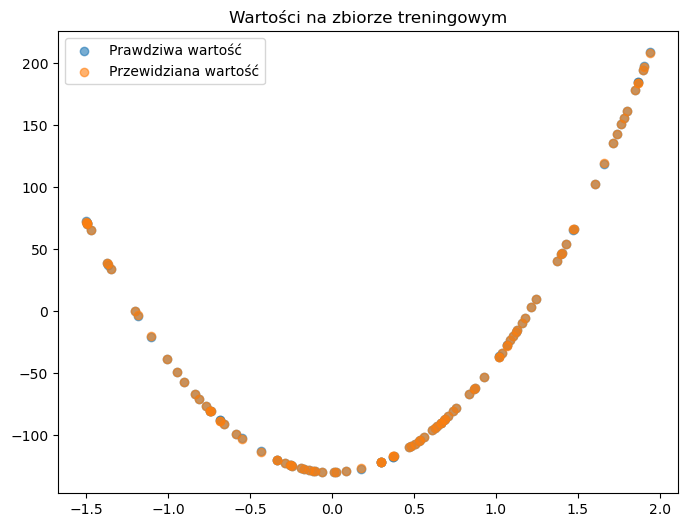

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 3.4869015240584483e-07
Nieznormalizowana finalna wartość funkcji straty: 0.03999243385060445


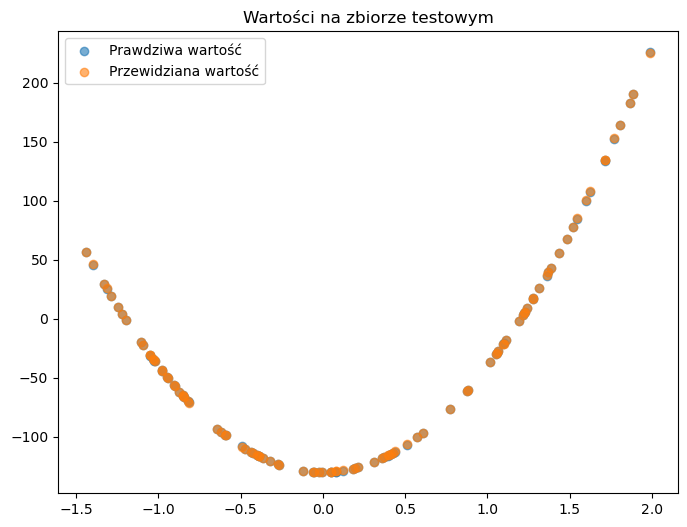

In [58]:
run_mlp(mlp_5, X_train, y_train, X_test, y_test)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 7.205132269945914e-07
Nieznormalizowana finalna wartość funkcji straty: 0.08263805952147893


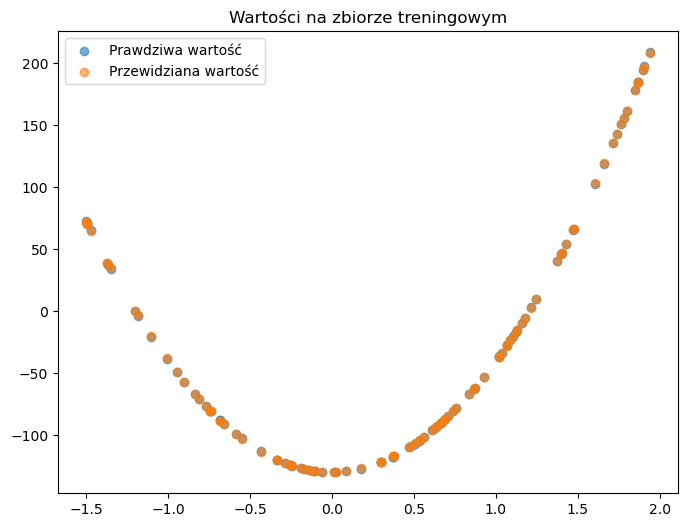

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 9.979626624676711e-07
Nieznormalizowana finalna wartość funkcji straty: 0.11445965849261784


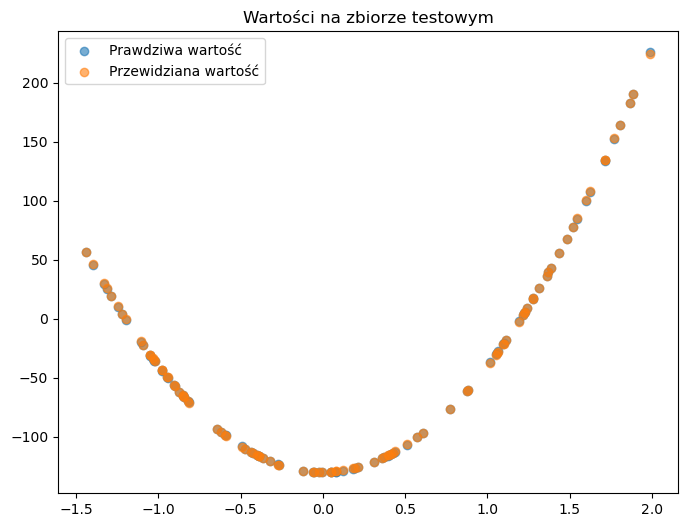

In [59]:
run_mlp(mlp_10, X_train, y_train, X_test, y_test)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 7.969728051321414e-07
Nieznormalizowana finalna wartość funkcji straty: 0.0914074629583501


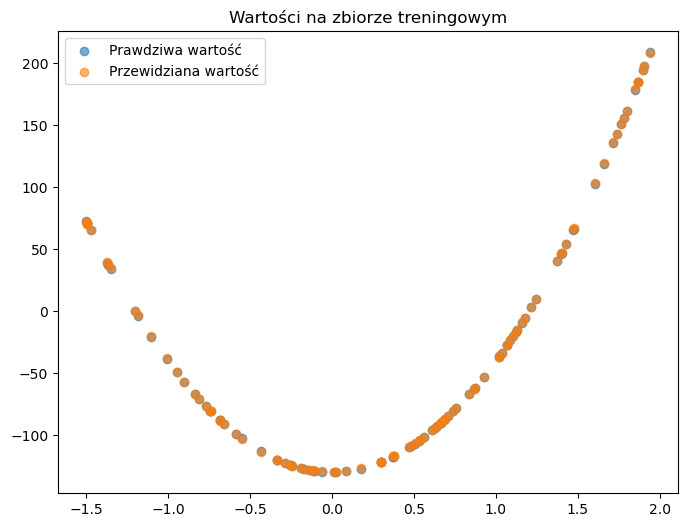

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 1.1218141454176308e-06
Nieznormalizowana finalna wartość funkcji straty: 0.12866459718962647


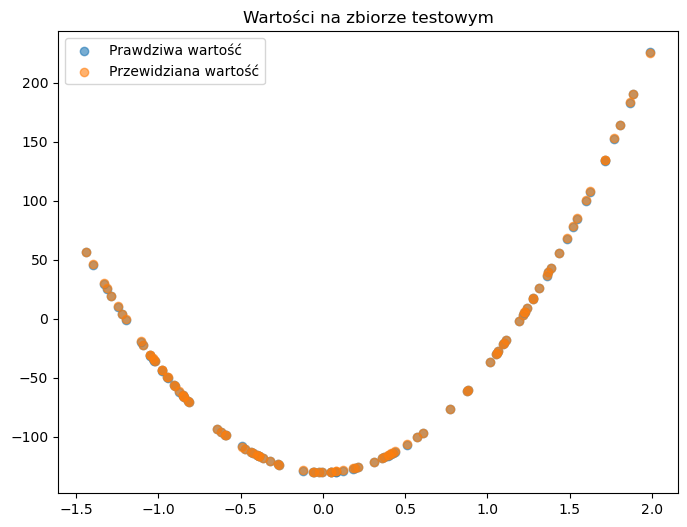

In [60]:
run_mlp(mlp_2_5, X_train, y_train, X_test, y_test)

Najlepszy wynik daje model z jedną warstwą ukrytymi z 5 neuronami.

# Regresja dla steps-large

In [30]:
# jedna warstwa ukryta o 5 neuronach
warstwa_1 = warstwa_liniowa(1, 5)
warstwa_1.wagi = model_5_steps[0].weight.data.cpu().numpy().T
warstwa_1.bias = model_5_steps[0].bias.data.cpu().numpy().reshape(1, -1)
warstwa_2 = warstwa_liniowa(5, 1)
warstwa_2.wagi = model_5_steps[2].weight.data.cpu().numpy().T
warstwa_2.bias = model_5_steps[2].bias.data.cpu().numpy().reshape(1, -1)
mlp_5 = MLP((warstwa_1, sigmoid(), warstwa_2))

# jedna warstwa ukryta o 10 neuronach
warstwa_1 = warstwa_liniowa(1, 10)
warstwa_1.wagi = model_10_steps[0].weight.data.cpu().numpy().T
warstwa_1.bias = model_10_steps[0].bias.data.cpu().numpy().reshape(1, -1)
warstwa_2 = warstwa_liniowa(10, 1)
warstwa_2.wagi = model_10_steps[2].weight.data.cpu().numpy().T
warstwa_2.bias = model_10_steps[2].bias.data.cpu().numpy().reshape(1, -1)
mlp_10 = MLP((warstwa_1, sigmoid(), warstwa_2))

# dwie warstwy ukryte po 5 neuronów
warstwa_1 = warstwa_liniowa(1, 5)
warstwa_1.wagi = model_2_5_steps[0].weight.data.cpu().numpy().T
warstwa_1.bias = model_2_5_steps[0].bias.data.cpu().numpy().reshape(1, -1)
warstwa_2 = warstwa_liniowa(5, 5)
warstwa_2.wagi = model_2_5_steps[2].weight.data.cpu().numpy().T
warstwa_2.bias = model_2_5_steps[2].bias.data.cpu().numpy().reshape(1, -1)
warstwa_3 = warstwa_liniowa(5, 1)
warstwa_3.wagi = model_2_5_steps[4].weight.data.cpu().numpy().T
warstwa_3.bias = model_2_5_steps[4].bias.data.cpu().numpy().reshape(1, -1)
mlp_2_5 = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3))

In [31]:
X_train = steps_large_train[['x']].to_numpy()
y_train = steps_large_train[['y']].to_numpy()
X_test = steps_large_test[['x']].to_numpy()
y_test = steps_large_test[['y']].to_numpy()

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 0.0061659007876587605
Nieznormalizowana finalna wartość funkcji straty: 355.15588536914464


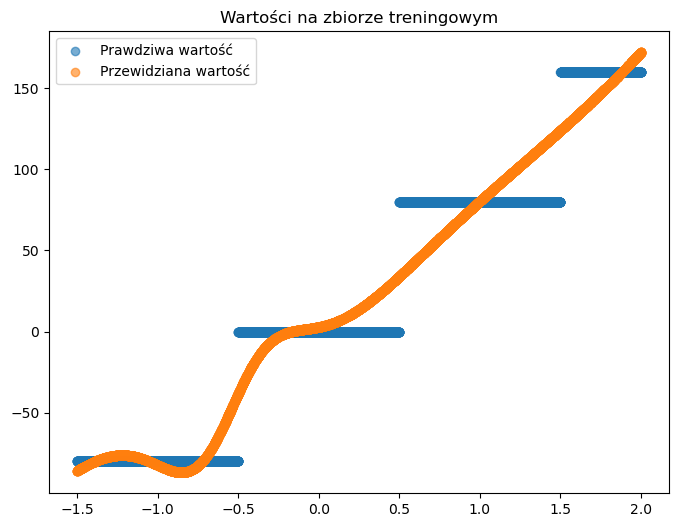

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 0.006157418833535052
Nieznormalizowana finalna wartość funkcji straty: 354.667324811619


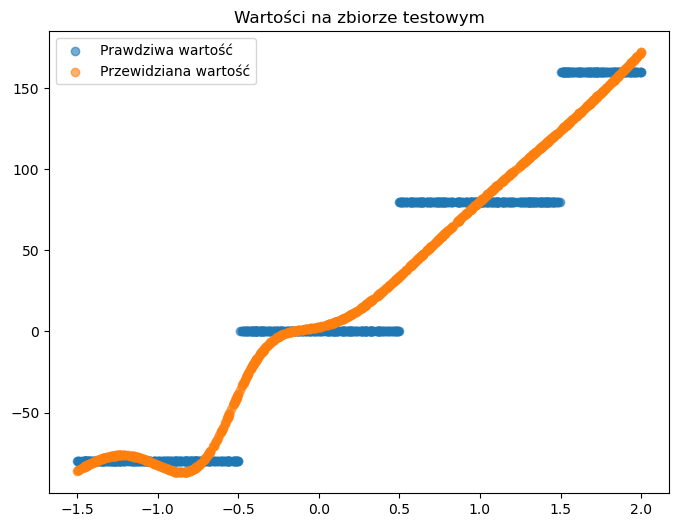

In [32]:
run_mlp(mlp_5, X_train, y_train, X_test, y_test)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 0.0060145758875080136
Nieznormalizowana finalna wartość funkcji straty: 346.4395711204616


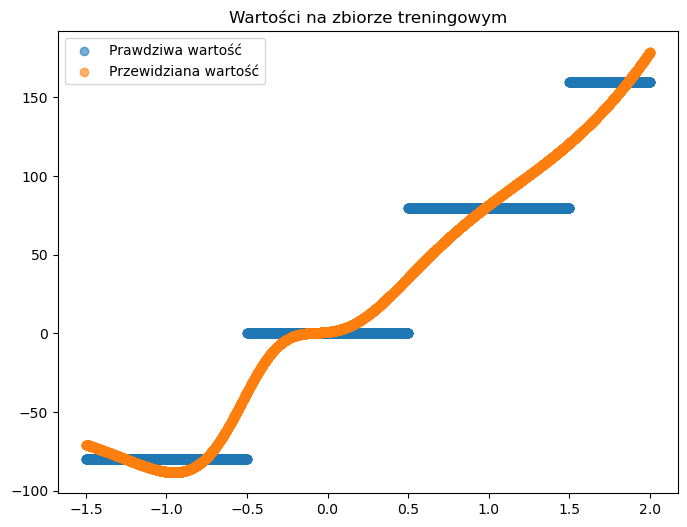

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 0.006022366164574633
Nieznormalizowana finalna wartość funkcji straty: 346.8882910794988


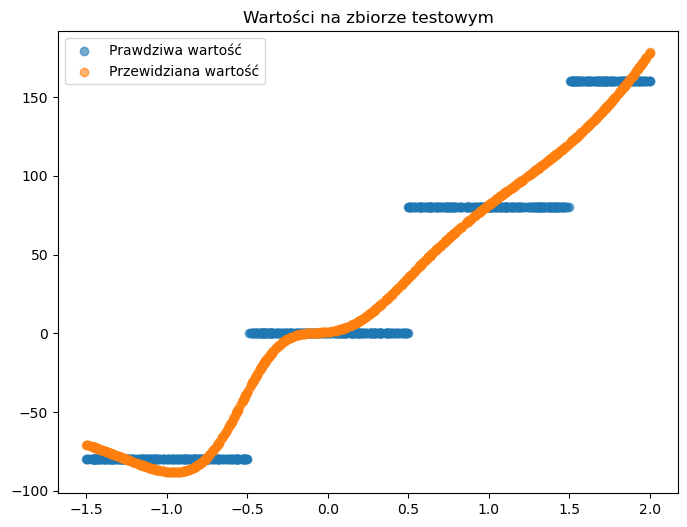

In [33]:
run_mlp(mlp_10, X_train, y_train, X_test, y_test)

Zbiór treningowy
Znormalizowana finalna wartość funkcji straty: 0.0017929180610560317
Nieznormalizowana finalna wartość funkcji straty: 103.27208031682743


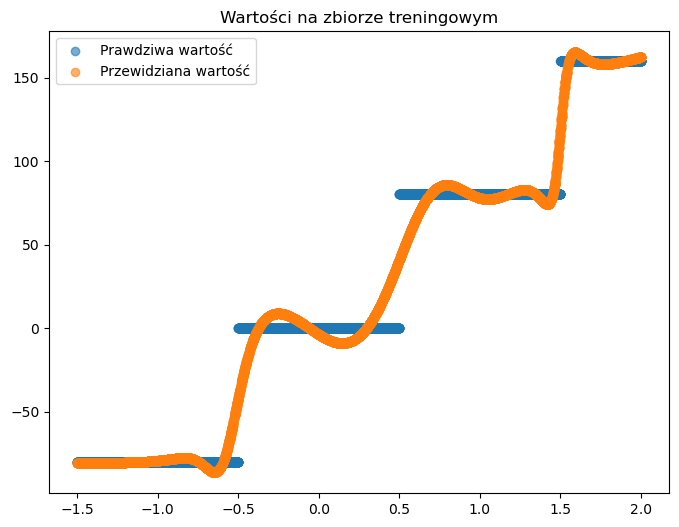

Zbiór testowy
Znormalizowana finalna wartość funkcji straty: 0.0015921145086556497
Nieznormalizowana finalna wartość funkcji straty: 91.70579569856542


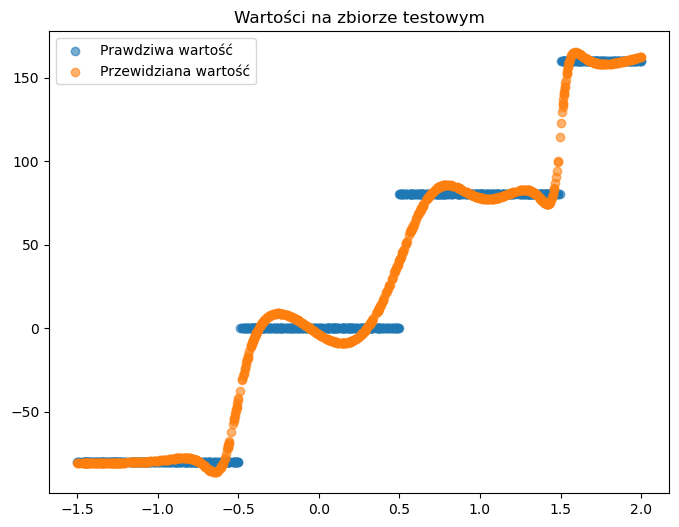

In [34]:
run_mlp(mlp_2_5, X_train, y_train, X_test, y_test)

Najlepszy wynik daje model z dwoma warstwami po 5 neuronów. Widać to dobrze na wykresie przewidzianych wartości.